# Data dictionary of the hotel bookings dataset

**Data source:** Antonio, N., de Almeida, A. and Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126 (file `hotel_bookings_dataset.csv`, identical to the CSV in `archive.zip`).
**Date:** 2026-11-04
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** This notebook describes every one of the 32 fields of the raw dataset (Part 1, task 1.1): its data type in the course taxonomy, whether it is temporal or geographic, its range or domain, its units and the precision the dashboard needs. The result is saved as a CSV (accessible version) and as several images for the Part 1 PDF.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: building the dictionary](#4.-Analysis:-building-the-dictionary)
5. [Accessible visualisation: dictionary images](#5.-Accessible-visualisation:-dictionary-images)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import textwrap
from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.textpath import TextPath
from IPython.display import Image

# Paths: the raw file is read-only; results go to this notebook's output folder,
# and the images used in the Part 1 text go to the part's images folder
RAW_FILE   = Path('../../Course information/hotel_bookings_dataset.csv')
OUTPUT_DIR = Path('data_dictionary_output')
IMAGES_DIR = Path('../images')
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

print('pandas', pd.__version__, '| matplotlib', matplotlib.__version__)
print('Raw file found:', RAW_FILE.exists())

pandas 2.3.3 | matplotlib 3.10.9
Raw file found: True


## 1. Data loading

In [2]:
# ── Load ──────────────────────────────────────────────────────────────────────

# Every column is read as text and nothing is turned into NaN, so we can see
# exactly how the file writes missing or "not applicable" values
raw_text = pd.read_csv(RAW_FILE, dtype=str, keep_default_na=False)

print(f'Rows: {raw_text.shape[0]:,} | Columns: {raw_text.shape[1]}')
raw_text.head()

Rows: 119,390 | Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NULL,NULL,0,Transient,0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NULL,NULL,0,Transient,0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NULL,NULL,0,Transient,75,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304,NULL,0,Transient,75,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240,NULL,0,Transient,98,0,1,Check-Out,2015-07-03


### Decision: read the file as text first

**Context:** by default pandas turns the strings `NA` and `NULL` into missing values (NaN) and then guesses each column's type.

**Decision taken:** the file is read with `dtype=str` and `keep_default_na=False`, so the placeholders stay visible as text and can be counted. Numbers are converted afterwards, field by field.

**Alternatives considered:** the default `read_csv` is simpler, but it would hide the difference between a real gap and `NULL`, which the source paper says means "not applicable" for `agent` and `company`.

> ⚠️ **Limitation:** nothing is changed here; the cleaning rules are decided in task 1.6 and applied only by `clean_hotel_bookings.py`.

## 2. Initial exploration

In [3]:
# ── Placeholders per field ───────────────────────────────────────────────────

# Count the text values that stand for "no value" in each column
placeholders = pd.DataFrame({
    'empty':     (raw_text == '').sum(),
    'NA':        (raw_text == 'NA').sum(),
    'NULL':      (raw_text == 'NULL').sum(),
    'Undefined': (raw_text == 'Undefined').sum(),
})
placeholders[placeholders.sum(axis=1) > 0]

,empty,NA,NULL,Undefined
children,0,4,0,0
meal,0,0,0,1169
country,0,0,488,0
market_segment,0,0,0,2
distribution_channel,0,0,0,5
agent,0,0,16340,0
company,0,0,112593,0


In [4]:
# ── Numeric profile ───────────────────────────────────────────────────────────

# Fields written as numbers (the IDs agent and company included, only to get their range)
numeric_fields = ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number',
                  'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights',
                  'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
                  'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
                  'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
                  'total_of_special_requests']

# Placeholders become NaN here (errors='coerce'); this copy is only used to measure ranges
numbers = raw_text[numeric_fields].apply(pd.to_numeric, errors='coerce')

numeric_profile = pd.DataFrame({
    'min':          numbers.min(),
    'max':          numbers.max(),
    'distinct':     numbers.nunique(),
    'not a number': numbers.isna().sum(),
})
numeric_profile

,min,max,distinct,not a number
is_canceled,0.00,1.0,2,0
lead_time,0.00,737.0,479,0
arrival_date_year,2015.00,2017.0,3,0
arrival_date_week_number,1.00,53.0,53,0
arrival_date_day_of_month,1.00,31.0,31,0
stays_in_weekend_nights,0.00,19.0,17,0
stays_in_week_nights,0.00,50.0,35,0
adults,0.00,55.0,14,0
children,0.00,10.0,5,4
babies,0.00,10.0,5,0


In [5]:
# ── Text profile ──────────────────────────────────────────────────────────────

text_fields = [c for c in raw_text.columns if c not in numeric_fields]

text_profile = pd.DataFrame({
    'distinct':      raw_text[text_fields].nunique(),
    'most frequent': raw_text[text_fields].apply(lambda col: col.value_counts().index[0]),
})
text_profile

,distinct,most frequent
hotel,2,City Hotel
arrival_date_month,12,August
meal,5,BB
country,178,PRT
market_segment,8,Online TA
distribution_channel,5,TA/TO
reserved_room_type,10,A
assigned_room_type,12,A
deposit_type,3,No Deposit
customer_type,4,Transient


In [6]:
# ── Checks that matter for the dictionary ────────────────────────────────────

# Country codes that are not three letters long (the paper describes ISO three-letter codes)
country_not_3_letters = raw_text.loc[raw_text['country'].str.len() != 3, 'country'].value_counts()
print('Country values that are not 3-letter codes:')
print(country_not_3_letters.to_string())

# Number of decimals written in the adr field
adr_decimals = raw_text['adr'].str.split('.').str[1].str.len().max()
print('\nMaximum decimals in adr:', int(adr_decimals))

# Range of the reservation status date
status_dates = pd.to_datetime(raw_text['reservation_status_date'])
print('reservation_status_date from', status_dates.min().date(), 'to', status_dates.max().date())

Country values that are not 3-letter codes:
country
CN      1279
NULL     488

Maximum decimals in adr: 2
reservation_status_date from 2014-10-17 to 2017-09-14


### Key findings

- The file has no empty cells. Missing or "not applicable" values are written as text: `NA` in `children`, `NULL` in `country`, `agent` and `company`, and the category `Undefined` in `meal`, `market_segment` and `distribution_channel`.
- `agent` and `company` look numeric but are identifiers: their numbers are labels, not quantities.
- `country` contains the two-letter value `CN` next to the three-letter codes; whether it means China (`CHN` also appears) is checked in task 1.2, not assumed here.
- `adr` is written with at most two decimals.

## 3. Cleaning and preparation

No cleaning is done in this notebook. The dictionary describes the **raw** data, so the ranges include the odd values (for example a negative `adr`). Cleaning rules are proposed in task 1.6, approved by the students, and applied only by `clean_hotel_bookings.py`.

## 4. Analysis: building the dictionary

In [7]:
# ── Descriptive part of the dictionary ───────────────────────────────────────

# meaning: from Table 1 of the source paper (Antonio et al., 2019), shortened.
# data_type and order: the course taxonomy (02-HowToApproachAVisualization):
#   categorical -> nominal / ordinal; numerical -> discrete / continuous, ratio / interval;
#   order -> sequential / divergent / cyclic.
# kind: tells the next cell how to compute the range or domain.
descriptions = [
    dict(field='hotel', kind='category',
         meaning='Hotel of the booking: Resort Hotel (Algarve) or City Hotel (Lisbon). Added when the two datasets of the paper were joined',
         data_type='Categorical, nominal', order='No order', nature='Geographic (hotel location)',
         units='No unit', precision='Label'),
    dict(field='is_canceled', kind='flag',
         meaning='The booking was cancelled (1) or not (0)',
         data_type='Categorical, nominal (binary)', order='No order', nature='Neither',
         units='No unit', precision='Count; rate in % with 1 decimal'),
    dict(field='lead_time', kind='number',
         meaning='Days between the booking entering the hotel system and the arrival date',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Temporal (duration)',
         units='Days', precision='Whole days'),
    dict(field='arrival_date_year', kind='number',
         meaning='Year of the arrival date',
         data_type='Numerical, discrete, interval', order='Sequential', nature='Temporal',
         units='Year', precision='Year'),
    dict(field='arrival_date_month', kind='month',
         meaning='Month of the arrival date (written as the month name)',
         data_type='Categorical, ordinal', order='Cyclic', nature='Temporal',
         units='Month', precision='Month'),
    dict(field='arrival_date_week_number', kind='number',
         meaning='Week number of the arrival date in its year',
         data_type='Numerical, discrete, interval', order='Cyclic', nature='Temporal',
         units='Week of the year', precision='Week'),
    dict(field='arrival_date_day_of_month', kind='number',
         meaning='Day of the month of the arrival date',
         data_type='Numerical, discrete, interval', order='Cyclic', nature='Temporal',
         units='Day of the month', precision='Day'),
    dict(field='stays_in_weekend_nights', kind='number',
         meaning='Weekend nights (Saturday or Sunday) stayed or booked to stay',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Temporal (duration)',
         units='Nights', precision='Whole nights'),
    dict(field='stays_in_week_nights', kind='number',
         meaning='Week nights (Monday to Friday) stayed or booked to stay',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Temporal (duration)',
         units='Nights', precision='Whole nights'),
    dict(field='adults', kind='number',
         meaning='Number of adults',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Persons', precision='Whole persons'),
    dict(field='children', kind='number',
         meaning='Number of children (paying and non-paying)',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Persons', precision='Whole persons'),
    dict(field='babies', kind='number',
         meaning='Number of babies',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Persons', precision='Whole persons'),
    dict(field='meal', kind='category',
         meaning='Meal package: SC or Undefined = no meal, BB = bed and breakfast, HB = half board, FB = full board',
         data_type='Categorical, ordinal (meals included)', order='Sequential', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='country', kind='code',
         meaning='Country of origin of the guest, as an ISO three-letter country code',
         data_type='Categorical, nominal', order='No order', nature='Geographic (guest origin)',
         units='No unit', precision='Country'),
    dict(field='market_segment', kind='category',
         meaning='Market segment of the booking (TA = travel agents, TO = tour operators)',
         data_type='Categorical, nominal', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='distribution_channel', kind='category',
         meaning='Channel used to make the booking (TA = travel agents, TO = tour operators, GDS = global distribution system)',
         data_type='Categorical, nominal', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='is_repeated_guest', kind='flag',
         meaning='The booking name belongs to a repeated guest (1) or not (0)',
         data_type='Categorical, nominal (binary)', order='No order', nature='Neither',
         units='No unit', precision='Count; share in % with 1 decimal'),
    dict(field='previous_cancellations', kind='number',
         meaning='Earlier bookings of the same customer that were cancelled',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Bookings', precision='Whole bookings'),
    dict(field='previous_bookings_not_canceled', kind='number',
         meaning='Earlier bookings of the same customer that were not cancelled',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Bookings', precision='Whole bookings'),
    dict(field='reserved_room_type', kind='category',
         meaning='Code of the room type reserved (letters, anonymised)',
         data_type='Categorical, nominal', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='assigned_room_type', kind='category',
         meaning='Code of the room type assigned; can differ from the reserved one (overbooking, guest request)',
         data_type='Categorical, nominal', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='booking_changes', kind='number',
         meaning='Changes made to the booking until check-in or cancellation',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Changes', precision='Whole changes'),
    dict(field='deposit_type', kind='category',
         meaning='Deposit to guarantee the booking: No Deposit, Non Refund (covers the whole stay) or Refundable (covers part of it)',
         data_type='Categorical, nominal', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='agent', kind='id',
         meaning='ID of the travel agency that made the booking; NULL = not made by an agency',
         data_type='Categorical, nominal (identifier)', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='company', kind='id',
         meaning='ID of the company that made or pays the booking; NULL = no company',
         data_type='Categorical, nominal (identifier)', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='days_in_waiting_list', kind='number',
         meaning='Days the booking waited before it was confirmed to the customer',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Temporal (duration)',
         units='Days', precision='Whole days'),
    dict(field='customer_type', kind='category',
         meaning='Type of booking: Transient, Transient-Party, Contract or Group',
         data_type='Categorical, nominal', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='adr', kind='number',
         meaning='Average daily rate: lodging revenue of the booking divided by its number of nights',
         data_type='Numerical, continuous, ratio', order='Sequential', nature='Neither',
         units='Money per night (currency not stated; probably euros)',
         precision='Whole euros (file has 2 decimals)'),
    dict(field='required_car_parking_spaces', kind='number',
         meaning='Car parking spaces the customer asked for',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Parking spaces', precision='Whole spaces'),
    dict(field='total_of_special_requests', kind='number',
         meaning='Special requests made by the customer (for example a twin bed or a high floor)',
         data_type='Numerical, discrete, ratio', order='Sequential', nature='Neither',
         units='Requests', precision='Whole requests'),
    dict(field='reservation_status', kind='category',
         meaning='Last status of the booking: Canceled, Check-Out or No-Show. Repeats is_canceled',
         data_type='Categorical, nominal', order='No order', nature='Neither',
         units='No unit', precision='Label'),
    dict(field='reservation_status_date', kind='date',
         meaning='Date on which the last status was set',
         data_type='Numerical, discrete, interval (date)', order='Sequential', nature='Temporal',
         units='Date (YYYY-MM-DD)', precision='Day'),
]

dictionary = pd.DataFrame(descriptions)

# Check that the dictionary covers exactly the 32 columns of the file, in the same order
print('Fields described:', len(dictionary))
print('Same fields and order as the file:', dictionary['field'].tolist() == raw_text.columns.tolist())

Fields described: 32
Same fields and order as the file: True


### Decision: how some fields are classified

**Context:** the course taxonomy depends on what a value *means*, not on how it is stored.

**Decision taken:**
- `is_canceled` and `is_repeated_guest` are stored as 0/1 but are **nominal** (two classes); the paper also calls them categorical. In the dashboard they become counts and percentages.
- `agent` and `company` are stored as numbers but are **nominal identifiers**: adding or averaging them has no meaning.
- Year, week, day of month and the status date are **interval**: their zero is a convention, so differences make sense but ratios do not. Month, week and day of month have a **cyclic** order.
- Counts (nights, persons, bookings, days) are **discrete ratio**: zero means "none" and "twice as many" makes sense.
- `adr` is **continuous ratio**. Its currency is not stated in the paper; euros is an assumption based on the hotels being in Portugal.
- `meal` is treated as **ordinal**, because the packages add meals in order (no meal < breakfast < half board < full board).

**Alternatives considered:** `arrival_date_year` could be ordinal (it has only three values); it is kept as interval because it is a point on the time line, which matters for a time axis.

> ⚠️ **Limitation:** "precision needed" is a first proposal for the dashboard; Parts 2 and 4 may change it.

In [8]:
# ── Range or domain, and missing values, computed from the data ──────────────

def describe_values(field, kind):
    """Text for the 'range or domain' column, computed from the raw data."""
    column = raw_text[field]
    if kind == 'number':
        values = pd.to_numeric(column, errors='coerce')
        return f'{values.min():g} to {values.max():g}'
    if kind == 'flag':
        return '0 = no, 1 = yes'
    if kind == 'month':
        return f'January to December ({column.nunique()} months)'
    if kind == 'date':
        dates = pd.to_datetime(column)
        return f'{dates.min().date()} to {dates.max().date()}'
    if kind == 'id':
        ids = pd.to_numeric(column, errors='coerce')
        return f'{ids.nunique()} IDs, from {ids.min():g} to {ids.max():g}'
    if kind == 'code':
        codes = column[column != 'NULL']
        top = ', '.join(codes.value_counts().index[:3])
        return f'{codes.nunique()} codes (most frequent: {top})'
    # kind == 'category': list the categories from most to least frequent
    categories = column.value_counts().index.tolist()
    return f'{len(categories)}: ' + ', '.join(categories)


PLACEHOLDERS = ['', 'NA', 'NULL', 'Undefined']   # text values that stand for "no value"

def count_missing(field):
    """Number of cells of the field that hold a placeholder instead of a value."""
    return int(raw_text[field].isin(PLACEHOLDERS).sum())


def missing_placeholder(field):
    """Which placeholder(s) the field uses, or a dash if it has none."""
    found = [p if p != '' else '(empty)' for p in PLACEHOLDERS if (raw_text[field] == p).any()]
    return ', '.join(found) if found else '—'


dictionary['range_domain'] = [describe_values(f, k) for f, k in zip(dictionary['field'], dictionary['kind'])]
dictionary['n_missing'] = [count_missing(f) for f in dictionary['field']]
dictionary['missing_placeholder'] = [missing_placeholder(f) for f in dictionary['field']]

dictionary[['field', 'data_type', 'order', 'range_domain', 'n_missing', 'missing_placeholder']]

,field,data_type,order,range_domain,n_missing,missing_placeholder
0,hotel,"Categorical, nominal",No order,"2: City Hotel, Resort Hotel",0,—
1,is_canceled,"Categorical, nominal (binary)",No order,"0 = no, 1 = yes",0,—
2,lead_time,"Numerical, discrete, ratio",Sequential,0 to 737,0,—
3,arrival_date_year,"Numerical, discrete, interval",Sequential,2015 to 2017,0,—
4,arrival_date_month,"Categorical, ordinal",Cyclic,January to December (12 months),0,—
5,arrival_date_week_number,"Numerical, discrete, interval",Cyclic,1 to 53,0,—
6,arrival_date_day_of_month,"Numerical, discrete, interval",Cyclic,1 to 31,0,—
7,stays_in_weekend_nights,"Numerical, discrete, ratio",Sequential,0 to 19,0,—
8,stays_in_week_nights,"Numerical, discrete, ratio",Sequential,0 to 50,0,—
9,adults,"Numerical, discrete, ratio",Sequential,0 to 55,0,—


In [9]:
# ── Summary of the classification ────────────────────────────────────────────

# Data type without the notes in brackets, and the first word of the temporal/geographic column
course_type = dictionary['data_type'].str.replace(r' \(.*\)', '', regex=True)
nature      = dictionary['nature'].str.split(' ').str[0]

print(course_type.value_counts().to_string())
print()
print(nature.value_counts().to_string())

data_type
Categorical, nominal             13
Numerical, discrete, ratio       12
Numerical, discrete, interval     4
Categorical, ordinal              2
Numerical, continuous, ratio      1

nature
Neither       21
Temporal       9
Geographic     2


## 5. Accessible visualisation: dictionary images

The dictionary is too wide for one table in an A4 PDF, so it is drawn as **two tables** (A: meaning and type; B: values), each split into **two images of 16 fields**. Each image is 16 cm wide (the text width of the PDF) with 8-point text, near-black text on white (contrast above 4.5:1, WCAG 1.4.3) and light grey bands on alternate rows, so the eye can follow a row (Gestalt principle of similarity). The CSV in the output folder is the accessible, machine-readable version.

In [10]:
# ── Drawing function ──────────────────────────────────────────────────────────

FONT_SIZE    = 8                     # points, at the final size in the PDF
LINE_HEIGHT  = FONT_SIZE * 1.3 / 72  # inches
PADDING      = 0.05                  # inches inside each cell
HEADER_COLOR = '#DDE3EA'
BAND_COLOR   = '#F3F3F3'
TEXT_COLOR   = '#1A1A1A'             # contrast about 17:1 on white

def text_width(text, bold=False):
    """Width in inches of a text written at FONT_SIZE (measured, not estimated)."""
    font = FontProperties(weight='bold' if bold else 'normal')
    return TextPath((0, 0), text, size=FONT_SIZE, prop=font).get_extents().width / 72


def wrap_cell(text, width_in, bold=False):
    """Split a cell text into lines that fit a column of width_in inches."""
    available = width_in - 2 * PADDING
    # Allow long field names to break after an underscore
    words = str(text).replace('_', '_ ').split(' ')
    lines, current = [], ''
    for word in words:
        joiner = '' if current.endswith('_') else ' '
        candidate = word if current == '' else current + joiner + word
        if current != '' and text_width(candidate, bold) > available:
            lines.append(current)
            current = word
        else:
            current = candidate
    lines.append(current)
    return lines


def draw_table(table, columns, headers, widths, file_name):
    """Draw a DataFrame as a table image whose width is the sum of widths (inches)."""
    rows = [headers] + table[columns].values.tolist()
    wrapped = [[wrap_cell(cell, w, bold=(i == 0)) for cell, w in zip(row, widths)]
               for i, row in enumerate(rows)]
    heights = [max(len(lines) for lines in row) * LINE_HEIGHT + 2 * PADDING for row in wrapped]

    total_width, total_height = sum(widths), sum(heights)
    fig = plt.figure(figsize=(total_width, total_height))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, total_width)
    ax.set_ylim(total_height, 0)
    ax.axis('off')

    y = 0
    for row_number, (row, height) in enumerate(zip(wrapped, heights)):
        # Background: header colour, then a light band on every second row
        if row_number == 0:
            ax.add_patch(plt.Rectangle((0, y), total_width, height, color=HEADER_COLOR))
        elif row_number % 2 == 0:
            ax.add_patch(plt.Rectangle((0, y), total_width, height, color=BAND_COLOR))
        x = 0
        for lines, width in zip(row, widths):
            ax.text(x + PADDING, y + PADDING, '\n'.join(lines), va='top', ha='left',
                    fontsize=FONT_SIZE, color=TEXT_COLOR, linespacing=1.3,
                    fontweight='bold' if row_number == 0 else 'normal')
            x += width
        y += height

    fig.savefig(IMAGES_DIR / file_name, dpi=200)
    plt.close(fig)
    return str(IMAGES_DIR / file_name)


print('Width of the word "Sequential" at 8 pt:', round(text_width('Sequential'), 2), 'inches')

Width of the word "Sequential" at 8 pt: 0.57 inches


In [11]:
# ── Table A: meaning and data type ────────────────────────────────────────────

columns_a = ['field', 'meaning', 'data_type', 'order', 'nature']
headers_a = ['Field', 'Meaning', 'Data type (course taxonomy)', 'Order', 'Temporal or geographic']
widths_a  = [1.45, 2.2, 1.05, 0.7, 0.9]    # inches, total 6.3 in = 16 cm

image_files = [
    draw_table(dictionary.iloc[:16], columns_a, headers_a, widths_a, 'dictionary_A1_meaning_type.png'),
    draw_table(dictionary.iloc[16:], columns_a, headers_a, widths_a, 'dictionary_A2_meaning_type.png'),
]
image_files

['../images/dictionary_A1_meaning_type.png',
 '../images/dictionary_A2_meaning_type.png']

In [12]:
# ── Table B: values, units and precision ─────────────────────────────────────

columns_b = ['field', 'range_domain', 'units', 'precision', 'n_missing_text', 'missing_placeholder']
headers_b = ['Field', 'Range or domain (raw data)', 'Units', 'Precision needed', '# Missing', 'Missing placeholder']
widths_b  = [1.45, 1.55, 0.92, 0.88, 0.62, 0.88]   # inches, total 6.3 in = 16 cm

# Counts with a thousands separator for the image (the CSV keeps the plain number)
dictionary['n_missing_text'] = dictionary['n_missing'].map('{:,}'.format)

image_files += [
    draw_table(dictionary.iloc[:16], columns_b, headers_b, widths_b, 'dictionary_B1_values.png'),
    draw_table(dictionary.iloc[16:], columns_b, headers_b, widths_b, 'dictionary_B2_values.png'),
]
image_files

['../images/dictionary_A1_meaning_type.png',
 '../images/dictionary_A2_meaning_type.png',
 '../images/dictionary_B1_values.png',
 '../images/dictionary_B2_values.png']

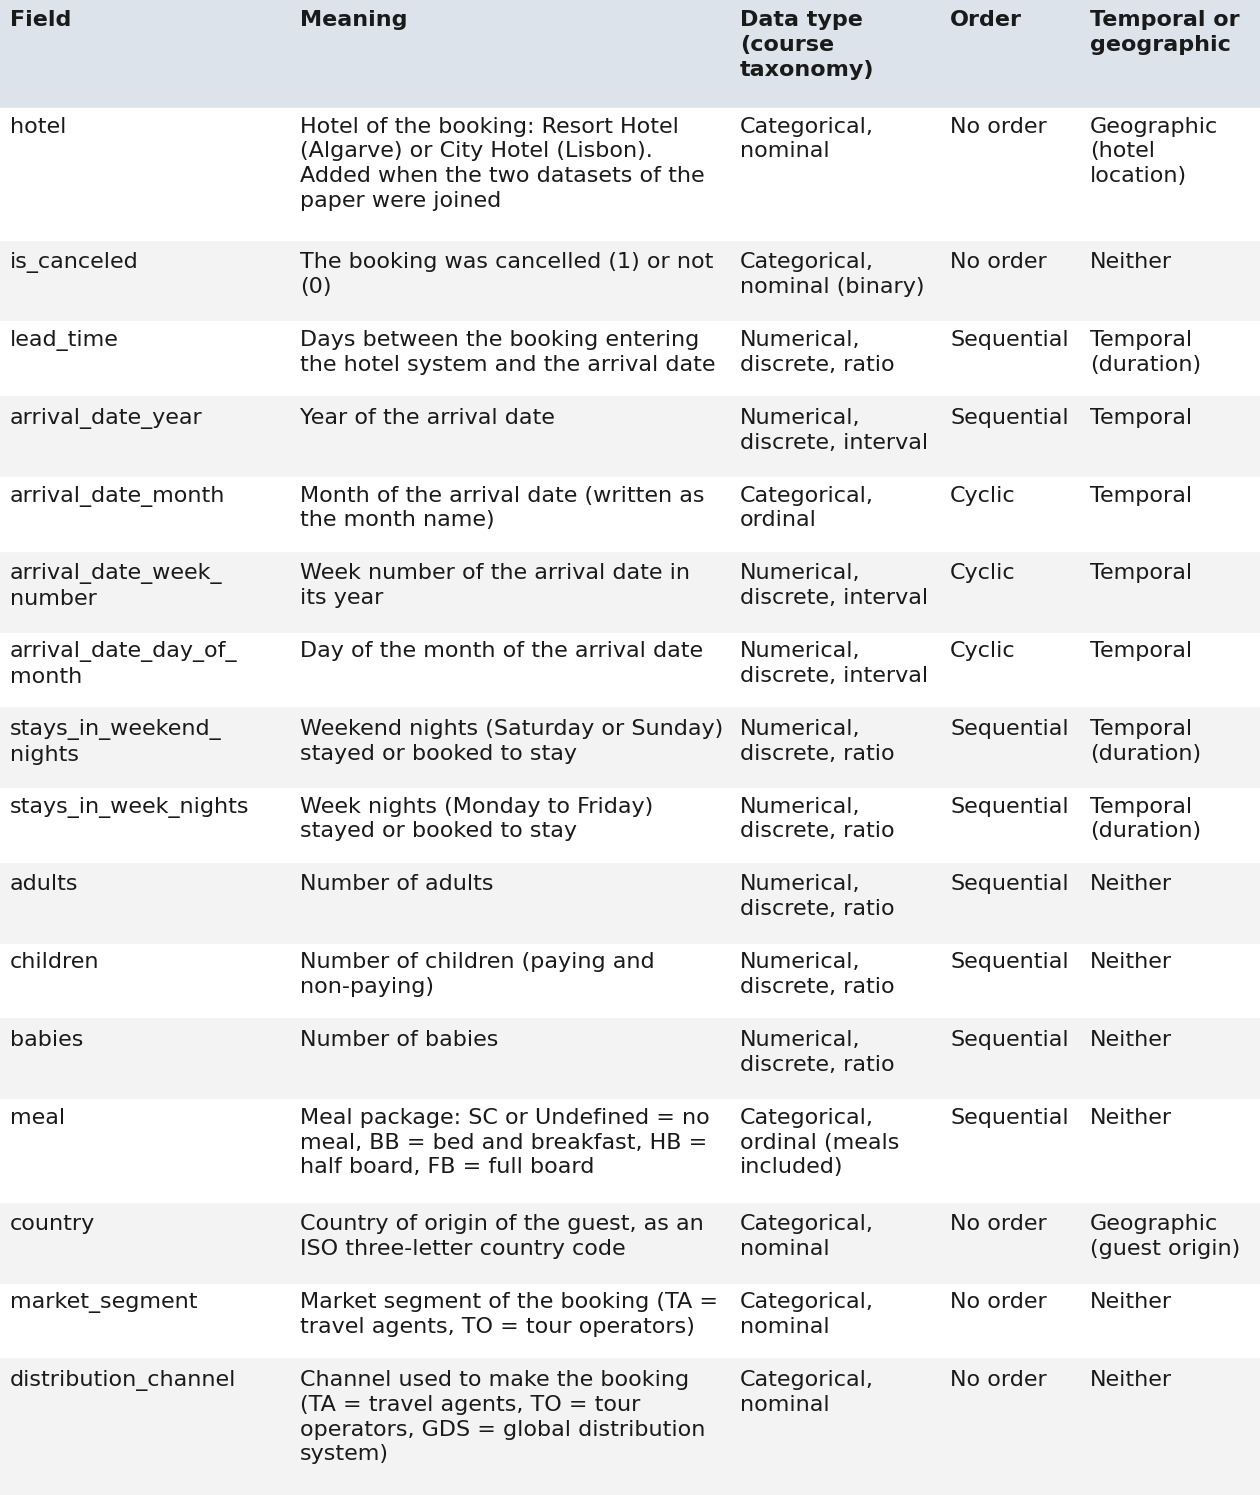

In [13]:
# ── Show the first image inside the notebook ─────────────────────────────────
Image(filename=image_files[0], width=760)

## 6. Export

In [14]:
# ── Export ────────────────────────────────────────────────────────────────────

# The CSV is the accessible version of the images (readable by a screen reader or a spreadsheet)
export_columns = ['field', 'meaning', 'data_type', 'order', 'nature', 'range_domain',
                  'units', 'precision', 'n_missing', 'missing_placeholder']
dictionary[export_columns].rename(columns={'n_missing': '# Missing',
                                           'missing_placeholder': 'Missing placeholder'}) \
    .to_csv(OUTPUT_DIR / 'data_dictionary.csv', index=False)

# The profiles used to fill the dictionary are kept as evidence
placeholders.to_csv(OUTPUT_DIR / 'placeholders_per_field.csv')
numeric_profile.to_csv(OUTPUT_DIR / 'numeric_profile.csv')
text_profile.to_csv(OUTPUT_DIR / 'text_profile.csv')

sorted(p.name for p in OUTPUT_DIR.iterdir())

['data_dictionary.csv',
 'numeric_profile.csv',
 'placeholders_per_field.csv',
 'text_profile.csv']

## Conclusions

### Main findings
1. Of the 32 fields, 15 are categorical (13 nominal, including two 0/1 flags and two identifiers, and 2 ordinal: month and meal) and 17 are numerical (12 discrete ratio counts, 4 discrete interval date parts, and 1 continuous ratio field, `adr`).
2. Nine fields are temporal: five give a point in time (year, month, week and day of arrival, and the status date) and four a duration (lead time, weekend nights, week nights, days in the waiting list). Two are geographic: `country` (guest origin) and, indirectly, `hotel` (Algarve or Lisbon).
3. Missing or "not applicable" values are written as text (`NA`, `NULL`, `Undefined`), never as empty cells.

### Limitations
- The currency of `adr` is not stated in the source; euros is an assumption.
- The ranges are those of the raw data and include values that task 1.2 will question.
- "Precision needed" is a first proposal and may change with the audience (Part 2).

### Suggested next steps
- Task 1.2: quantify duplicates, placeholders and odd values (for example `CN` next to `CHN`, a negative `adr`, bookings with 0 adults).